# Mobile-FOG (DWPose-m + PatientLock): Training & Evaluasi 4 Model — Fixed Split (23/5/7) + 35-Fold LOSO
**Target Lingkungan:** Kaggle Notebook — **Accelerator: GPU T4 x2** (`2× NVIDIA T4`)

Notebook ini langsung memakai output ekstraksi `DWPose-m` + PatientLock yang sudah ada (**TIDAK perlu ekstraksi ulang**), dan menjalankan dua tahap evaluasi lengkap:
- **Tahap A — Fixed Split Resmi (`23 / 5 / 7`)** pada 4 kombinasi skenario (`A_15hz`, `A_30hz`, `B_15hz`, `B_30hz`) × 4 model (`LightGBM+FFT`, `Light ST-GCN-cls`, `Pure Bi-Mamba`, `Hybrid GCN+Bi-Mamba`) agar bisa dibandingkan *apple-to-apple* dengan estimator pose lain (YOLO26n, MediaPipe).
- **Tahap B — 35-Fold LOSO (*Leave-One-Subject-Out*) Paralel `2× T4`** pada skenario terbaik (atau pilihan di `LOSO_SCENARIO`):
  - Menggabungkan `X` mentah (`train + val + test`, `35` subjek) lalu *fit* `StandardScaler` **ulang di setiap fold** (*Zero Data Leakage*).
  - Menyisihkan `5` subjek *inner-val* (terstratifikasi FoG aktif + kontrol) untuk *early stopping* & *threshold tuning*.
  - Melaporkan **Global OOF Metrics** (`35` subjek penuh) dan **Per-Subject `mean ± std`** (`26` subjek FoG aktif untuk AUC/F1/Sens, `35` subjek untuk Spec).


In [1]:
!pip install -q lightgbm scikit-learn matplotlib seaborn

import os
import json
import math
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import lightgbm as lgb
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

SEED = 42
seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE} | GPUs: {torch.cuda.device_count()} | PyTorch: {torch.__version__} | LightGBM: {lgb.__version__}")


Device: cuda | GPUs: 2 | PyTorch: 2.11.0+cu130 | LightGBM: 4.6.0


In [2]:
# ==============================================================================
# TEMPAT MELETAKKAN PATH FOLDER HASIL EKSTRAKSI (EDIT BAGIAN INI)
# ==============================================================================
# Arahkan ke folder 'mobilefog_dwpose_patientlock' yang berisi '02_processed_scenarios/D_windowed_stgcn_cls/'
# Contoh Kaggle Dataset : Path("/kaggle/input/mobilefog-dwpose-extracted/mobilefog_dwpose_patientlock")
# Contoh Sesi Sama      : Path("/kaggle/working/mobilefog_dwpose_patientlock")
DATA_DIR = Path("/kaggle/input/notebooks/sultandaulay/biomed-dwpose/mobilefog_dwpose_patientlock")

# Folder output hasil training, checkpoint, grafik, & tabel CSV
RESULTS_DIR = Path("/kaggle/working/mobilefog_training_results")

# Auto-detect fallback (cek /kaggle/working dan /kaggle/input)
if not (DATA_DIR / "02_processed_scenarios" / "D_windowed_stgcn_cls").exists():
    detected = None
    for root in [Path("/kaggle/working"), Path("/kaggle/input"), Path(".")]:
        if not root.exists():
            continue
        for d_dir in root.rglob("D_windowed_stgcn_cls"):
            cand = d_dir.parent.parent
            if cand.is_dir() and (cand / "02_processed_scenarios" / "D_windowed_stgcn_cls").exists():
                detected = cand
                break
        if detected is not None:
            break
    if detected is not None:
        print(f"[AUTO-DETECT] DATA_DIR ditemukan otomatis di: {detected}")
        DATA_DIR = detected
    else:
        raise FileNotFoundError(
            f"Folder '02_processed_scenarios/D_windowed_stgcn_cls' tidak ditemukan di {DATA_DIR}.\n"
            "Silakan isi DATA_DIR dengan lokasi folder 'mobilefog_dwpose_patientlock' hasil notebook ekstraksi sebelumnya."
        )

SCEN_D_ROOT = DATA_DIR / "02_processed_scenarios" / "D_windowed_stgcn_cls"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "checkpoints").mkdir(exist_ok=True)
(RESULTS_DIR / "figures").mkdir(exist_ok=True)

# (OPSIONAL RESUME KAGGLE >12 JAM) Arahkan ke output versi notebook sebelumnya di /kaggle/input/...
# Contoh: Path("/kaggle/input/mobilefog-dwpose-training/mobilefog_training_results")
PREV_RESULTS_DIR = None
if PREV_RESULTS_DIR is not None and Path(PREV_RESULTS_DIR).exists():
    import shutil
    shutil.copytree(PREV_RESULTS_DIR, RESULTS_DIR, dirs_exist_ok=True)
    print(f"[RESUME] Menyalin checkpoint & fold sebelumnya dari {PREV_RESULTS_DIR} -> {RESULTS_DIR}")

# ==============================================================================
# HYPERPARAMETER TRAINING (AMAN UNTUK T4 GPU < 1 GB VRAM)
# ==============================================================================
SCENARIOS_TO_RUN = [
    ("A_15hz", "from_A_baseline_norm_15hz", 15.0),
    ("A_30hz", "from_A_baseline_norm_30hz", 30.0),
    ("B_15hz", "from_B_denoised_hampel_accel_15hz", 15.0),
    ("B_30hz", "from_B_denoised_hampel_accel_30hz", 30.0),
]

LABEL_KEY = "y_maj"          # Label utama: mayoritas frame dalam window 2s adalah FoG
EPOCHS = 40                  # Early stopping akan berhenti lebih cepat jika val PR-AUC stagnan
PATIENCE = 10
BATCH_SIZE = 64
LR = 1.5e-3
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0
MIN_RUN_WINDOWS = 2          # Post-processing: hapus kedipan FoG terisolasi (1 window tunggal)

# Konfigurasi 35-Fold LOSO (Tahap B)
RUN_LOSO = True
LOSO_SCENARIO = "B_15hz"     # ditetapkan tanpa melihat skor test, sama untuk semua estimator ("AUTO_BEST" memilih berdasarkan test PR-AUC)
LOSO_EPOCHS = 30
LOSO_PATIENCE = 8
LOSO_INNER_VAL_SUBJECTS = 5  # 5 subjek inner-val di tiap fold (terstratifikasi FoG aktif & kontrol)

print(f"SCEN_D_ROOT : {SCEN_D_ROOT}")
print(f"RESULTS_DIR : {RESULTS_DIR}")
for tag, sub, hz in SCENARIOS_TO_RUN:
    assert (SCEN_D_ROOT / sub / "train.npz").exists(), f"Missing {sub}/train.npz"
print("Seluruh 4 skenario (A/B x 15Hz/30Hz) terverifikasi ada.")


SCEN_D_ROOT : /kaggle/input/notebooks/sultandaulay/biomed-dwpose/mobilefog_dwpose_patientlock/02_processed_scenarios/D_windowed_stgcn_cls
RESULTS_DIR : /kaggle/working/mobilefog_training_results
Seluruh 4 skenario (A/B x 15Hz/30Hz) terverifikasi ada.


In [3]:
# ==============================================================================
# DATASET, MATRIKS GRAF LB6, METRIK KLINIS & POST-PROCESSING
# ==============================================================================
def build_lb6_graph_A() -> np.ndarray:
    """Matriks ketetanggaan spasial A (3, 6, 6): Root, Centripetal, Centrifugal."""
    V = 6
    # 0:L_Hip, 1:R_Hip, 2:L_Knee, 3:R_Knee, 4:L_Ankle, 5:R_Ankle
    self_link = np.eye(V, dtype=np.float32)
    inward_edges = [(2, 0), (3, 1), (4, 2), (5, 3), (0, 1)]
    inward = np.zeros((V, V), dtype=np.float32)
    outward = np.zeros((V, V), dtype=np.float32)
    for i, j in inward_edges:
        inward[j, i] = 1.0
        outward[i, j] = 1.0

    def norm_adj(M):
        deg = M.sum(axis=0, keepdims=True)
        deg[deg == 0] = 1.0
        return M / deg

    return np.stack([norm_adj(self_link), norm_adj(inward), norm_adj(outward)], axis=0)


A_LB6 = build_lb6_graph_A()


class MobileFogWindowDataset(Dataset):
    def __init__(self, npz_data, label_key: str = "y_maj", use_scaled: bool = True):
        self.X = npz_data["X_scaled"].astype(np.float32) if use_scaled else npz_data["X"].astype(np.float32)
        self.y = npz_data[label_key].astype(np.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return torch.from_numpy(self.X[idx]), torch.tensor(self.y[idx], dtype=torch.float32)


def find_best_threshold(y_true: np.ndarray, y_prob: np.ndarray) -> float:
    """Cari threshold optimal untuk F1-FoG HANYA di validation set."""
    best_thr, best_f1 = 0.5, -1.0
    for thr in np.linspace(0.15, 0.85, 71):
        pred = (y_prob >= thr).astype(np.int64)
        score = f1_score(y_true, pred, zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_thr = float(thr)
    return best_thr


def apply_min_duration_filter(y_pred: np.ndarray, trial_ids: np.ndarray, min_run: int = 2) -> np.ndarray:
    """Post-processing per trial: hapus kedipan positif yang lebih pendek dari min_run window."""
    out = y_pred.copy()
    for tid in np.unique(trial_ids):
        idx = np.where(trial_ids == tid)[0]
        seq = out[idx]
        n = len(seq)
        i = 0
        while i < n:
            if seq[i] == 1:
                j = i
                while j < n and seq[j] == 1:
                    j += 1
                if (j - i) < min_run:
                    seq[i:j] = 0
                i = j
            else:
                i += 1
        out[idx] = seq
    return out


def compute_clinical_metrics(y_true: np.ndarray, y_prob: np.ndarray, thr: float, trial_ids: np.ndarray | None = None, min_run: int = 1) -> dict:
    y_true_i = y_true.astype(np.int64)
    y_pred = (y_prob >= thr).astype(np.int64)
    if trial_ids is not None and min_run > 1:
        y_pred = apply_min_duration_filter(y_pred, trial_ids, min_run=min_run)

    tn, fp, fn, tp = confusion_matrix(y_true_i, y_pred, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    return {
        "roc_auc": float(roc_auc_score(y_true_i, y_prob)),
        "pr_auc": float(average_precision_score(y_true_i, y_prob)),
        "f1_fog": float(f1_score(y_true_i, y_pred, zero_division=0)),
        "precision": float(precision_score(y_true_i, y_pred, zero_division=0)),
        "sensitivity": float(sens),
        "specificity": float(spec),
        "bal_acc": float(0.5 * (sens + spec)),
        "thr": float(thr),
        "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn),
    }


In [4]:
# ==============================================================================
# DEFINISI 3 ARSITEKTUR DEEP LEARNING RINGAN (PYTORCH MURNI)
# ==============================================================================

# --- 1. Lightweight ST-GCN-cls ---
class SpatialGraphConv(nn.Module):
    def __init__(self, in_c: int, out_c: int, A: np.ndarray):
        super().__init__()
        self.register_buffer("A", torch.tensor(A, dtype=torch.float32))  # (K, V, V)
        K, V, _ = A.shape
        self.K = K
        self.edge_mask = nn.Parameter(torch.ones(K, V, V))
        self.conv = nn.Conv2d(in_c, out_c * K, kernel_size=1)

    def forward(self, x):
        # x: (B, C, T, V)
        B, _, T, V = x.shape
        x = self.conv(x).view(B, self.K, -1, T, V)
        A_eff = self.A * self.edge_mask
        return torch.einsum("bkctv,kvw->bctw", x, A_eff).contiguous()


class STGCNBlock(nn.Module):
    def __init__(self, in_c: int, out_c: int, A: np.ndarray, stride: int = 1, dropout: float = 0.25):
        super().__init__()
        self.sgcn = SpatialGraphConv(in_c, out_c, A)
        self.bn1 = nn.BatchNorm2d(out_c)
        # Depthwise-separable temporal conv (1x9)
        self.tconv_dw = nn.Conv2d(out_c, out_c, kernel_size=(9, 1), stride=(stride, 1), padding=(4, 0), groups=out_c)
        self.tconv_pw = nn.Conv2d(out_c, out_c, kernel_size=1)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.drop = nn.Dropout(dropout)
        if in_c != out_c or stride != 1:
            self.residual = nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=1, stride=(stride, 1)),
                nn.BatchNorm2d(out_c),
            )
        else:
            self.residual = nn.Identity()

    def forward(self, x):
        res = self.residual(x)
        h = F.relu(self.bn1(self.sgcn(x)))
        h = self.bn2(self.tconv_pw(self.tconv_dw(h)))
        return F.relu(self.drop(h) + res)


class LightweightSTGCN(nn.Module):
    def __init__(self, in_c: int, A: np.ndarray, dropout: float = 0.25):
        super().__init__()
        self.data_bn = nn.BatchNorm1d(in_c * A.shape[1])
        self.blocks = nn.Sequential(
            STGCNBlock(in_c, 32, A, stride=1, dropout=dropout),
            STGCNBlock(32, 64, A, stride=2, dropout=dropout),
            STGCNBlock(64, 64, A, stride=2, dropout=dropout),
        )
        self.head = nn.Linear(64, 1)

    def forward(self, x):
        # x: (B, C, T, V)
        B, C, T, V = x.shape
        x = x.permute(0, 1, 3, 2).contiguous().view(B, C * V, T)
        x = self.data_bn(x).view(B, C, V, T).permute(0, 1, 3, 2).contiguous()
        h = self.blocks(x)                 # (B, 64, T', V)
        h = h.mean(dim=(2, 3))             # Global Avg Pooling
        return self.head(h).squeeze(-1)    # (B,) logits


# --- 2. Pure-PyTorch Bidirectional Mamba (Bi-Mamba) Block ---
class RMSNorm(nn.Module):
    def __init__(self, d_model: int, eps: float = 1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d_model))
        self.eps = eps

    def forward(self, x):
        rms = torch.rsqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return x * rms * self.weight


class SelectiveSSM1D(nn.Module):
    """Pure-PyTorch Selective SSM (S6) scan: 100% kompatibel Kaggle tanpa custom CUDA compile."""
    def __init__(self, d_inner: int, d_state: int = 16, d_conv: int = 4):
        super().__init__()
        self.d_inner = d_inner
        self.d_state = d_state
        self.conv1d = nn.Conv1d(d_inner, d_inner, kernel_size=d_conv, padding=d_conv - 1, groups=d_inner)
        self.x_proj = nn.Linear(d_inner, d_inner + 2 * d_state, bias=False)
        self.dt_proj = nn.Linear(d_inner, d_inner, bias=True)
        A = torch.arange(1, d_state + 1, dtype=torch.float32).unsqueeze(0).repeat(d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(d_inner))

    def forward(self, u):
        # u: (B, L, d_inner)
        B, L, D = u.shape
        x = self.conv1d(u.transpose(1, 2))[:, :, :L].transpose(1, 2)
        x = F.silu(x)

        proj = self.x_proj(x)
        dt_in, B_t, C_t = torch.split(proj, [D, self.d_state, self.d_state], dim=-1)
        dt = F.softplus(self.dt_proj(dt_in))            # (B, L, D)
        A = -torch.exp(self.A_log)                      # (D, N)

        # Sequential selective scan (cepat untuk L=30..60 di T4)
        h = torch.zeros(B, D, self.d_state, device=u.device, dtype=u.dtype)
        ys = []
        for t in range(L):
            dt_t = dt[:, t, :].unsqueeze(-1)            # (B, D, 1)
            dA = torch.exp(dt_t * A.unsqueeze(0))       # (B, D, N)
            dB_x = dt_t * B_t[:, t, :].unsqueeze(1) * x[:, t, :].unsqueeze(-1)
            h = dA * h + dB_x
            y_t = (h * C_t[:, t, :].unsqueeze(1)).sum(dim=-1)
            ys.append(y_t)
        y = torch.stack(ys, dim=1) + x * self.D.unsqueeze(0).unsqueeze(0)
        return y


class BiMambaBlock(nn.Module):
    def __init__(self, d_model: int = 64, expand: int = 2, d_state: int = 16, dropout: float = 0.2):
        super().__init__()
        d_inner = d_model * expand
        self.norm = RMSNorm(d_model)
        self.in_proj = nn.Linear(d_model, d_inner * 2, bias=False)
        self.ssm_fwd = SelectiveSSM1D(d_inner, d_state=d_state)
        self.ssm_bwd = SelectiveSSM1D(d_inner, d_state=d_state)
        self.out_proj = nn.Linear(d_inner, d_model, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        # x: (B, L, d_model)
        h = self.norm(x)
        u, z = self.in_proj(h).chunk(2, dim=-1)
        gate = F.silu(z)
        y_fwd = self.ssm_fwd(u) * gate
        y_bwd = torch.flip(self.ssm_bwd(torch.flip(u, dims=[1])), dims=[1]) * gate
        out = self.out_proj(y_fwd + y_bwd)
        return x + self.drop(out)


class PureBiMamba(nn.Module):
    def __init__(self, in_c: int, num_joints: int = 6, d_model: int = 64, n_layers: int = 2, dropout: float = 0.2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Linear(in_c * num_joints, d_model),
            nn.LayerNorm(d_model),
            nn.SiLU(),
        )
        self.layers = nn.ModuleList([BiMambaBlock(d_model=d_model, expand=2, d_state=16, dropout=dropout) for _ in range(n_layers)])
        self.norm_f = RMSNorm(d_model)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        # x: (B, C, T, V) -> (B, T, C*V)
        B, C, T, V = x.shape
        h = x.permute(0, 2, 1, 3).contiguous().view(B, T, C * V)
        h = self.stem(h)
        for blk in self.layers:
            h = blk(h)
        h = self.norm_f(h).mean(dim=1)
        return self.head(h).squeeze(-1)


# --- 3. Hybrid Spatial-GCN + Bi-Mamba ---
class HybridGCNBiMamba(nn.Module):
    def __init__(self, in_c: int, A: np.ndarray, d_model: int = 64, n_mamba: int = 2, dropout: float = 0.2):
        super().__init__()
        self.gcn1 = SpatialGraphConv(in_c, 32, A)
        self.bn1 = nn.BatchNorm2d(32)
        self.gcn2 = SpatialGraphConv(32, d_model, A)
        self.bn2 = nn.BatchNorm2d(d_model)
        self.drop_g = nn.Dropout(dropout)
        self.mamba_layers = nn.ModuleList([BiMambaBlock(d_model=d_model, expand=2, d_state=16, dropout=dropout) for _ in range(n_mamba)])
        self.norm_f = RMSNorm(d_model)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        # x: (B, C, T, V)
        h = F.silu(self.bn1(self.gcn1(x)))
        h = self.drop_g(F.silu(self.bn2(self.gcn2(h))))
        # Joint pool -> (B, T, d_model)
        h = h.mean(dim=-1).transpose(1, 2).contiguous()
        for blk in self.mamba_layers:
            h = blk(h)
        h = self.norm_f(h).mean(dim=1)
        return self.head(h).squeeze(-1)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print("Jumlah Parameter (untuk C=9, V=6):")
print(f"  Lightweight ST-GCN-cls    : {count_params(LightweightSTGCN(9, A_LB6)):,}")
print(f"  Pure Bi-Mamba (2 blok)    : {count_params(PureBiMamba(9, 6)):,}")
print(f"  Hybrid GCN + Bi-Mamba     : {count_params(HybridGCNBiMamba(9, A_LB6)):,}")


Jumlah Parameter (untuk C=9, V=6):
  Lightweight ST-GCN-cls    : 38,801
  Pure Bi-Mamba (2 blok)    : 212,289
  Hybrid GCN + Bi-Mamba     : 216,345


In [5]:
# ==============================================================================
# MODEL 2: EKSTRAKSI FITUR SPEKTRAL FFT (MOORE'S FREEZE INDEX) + LIGHTGBM
# ==============================================================================
def extract_fft_kinematic_features(X_raw: np.ndarray, fs: float) -> np.ndarray:
    """Ekstrak fitur spektral (0.5-3 Hz vs 3-8 Hz) & kinematika dari tensor (N, C, T, 6)."""
    # X_raw channel order (Scenario A/B): 0:x, 1:y, 2:conf, 3:dx, 4:dy, ...
    N, C, T, V = X_raw.shape
    freqs = np.fft.rfftfreq(T, d=1.0 / fs)
    loco_mask = (freqs >= 0.5) & (freqs <= 3.0)
    freeze_mask = (freqs > 3.0) & (freqs <= min(8.0, 0.49 * fs))

    feats = []
    # 1) Statistik dasar per kanal & sendi (mean, std, max abs) pada x, y, dx, dy
    for c_idx in [0, 1, 3, 4]:
        arr = X_raw[:, c_idx, :, :]  # (N, T, 6)
        feats.append(arr.mean(axis=1))
        feats.append(arr.std(axis=1))
        feats.append(np.max(np.abs(arr), axis=1))

    # 2) Moore's Freeze Index & energi pita pada sinyal kecepatan vertikal/horizontal (dx, dy)
    for c_idx in [3, 4]:
        sig = X_raw[:, c_idx, :, :] - X_raw[:, c_idx, :, :].mean(axis=1, keepdims=True)
        psd = np.abs(np.fft.rfft(sig, axis=1)) ** 2  # (N, F, 6)
        e_loco = psd[:, loco_mask, :].sum(axis=1) + 1e-8
        e_freeze = psd[:, freeze_mask, :].sum(axis=1) + 1e-8
        fi = np.log1p(e_freeze / e_loco)
        feats.extend([np.log1p(e_loco), np.log1p(e_freeze), fi])

    # 3) Asimetri bilateral |Kiri - Kanan| & lebar langkah antar engkel/lutut
    # LB6: (0:L_Hip, 1:R_Hip), (2:L_Knee, 3:R_Knee), (4:L_Ankle, 5:R_Ankle)
    for l_j, r_j in [(0, 1), (2, 3), (4, 5)]:
        dist_xy = np.sqrt(
            (X_raw[:, 0, :, l_j] - X_raw[:, 0, :, r_j]) ** 2
            + (X_raw[:, 1, :, l_j] - X_raw[:, 1, :, r_j]) ** 2
        )  # (N, T)
        asym_v = np.abs(X_raw[:, 3, :, l_j] - X_raw[:, 3, :, r_j]) + np.abs(X_raw[:, 4, :, l_j] - X_raw[:, 4, :, r_j])
        feats.append(dist_xy.mean(axis=1, keepdims=True))
        feats.append(dist_xy.std(axis=1, keepdims=True))
        feats.append(asym_v.mean(axis=1, keepdims=True))
        feats.append(asym_v.std(axis=1, keepdims=True))

    # 4) Rata-rata confidence
    feats.append(X_raw[:, 2, :, :].mean(axis=1))

    F_mat = np.concatenate(feats, axis=1).astype(np.float32)
    return np.nan_to_num(F_mat, nan=0.0, posinf=0.0, neginf=0.0)


def train_eval_lightgbm(d_tr, d_va, d_te, fs: float, label_key: str, save_prefix: Path):
    t0 = time.time()
    X_tr = extract_fft_kinematic_features(d_tr["X"], fs)
    X_va = extract_fft_kinematic_features(d_va["X"], fs)
    X_te = extract_fft_kinematic_features(d_te["X"], fs)

    y_tr = d_tr[label_key].astype(np.int64)
    y_va = d_va[label_key].astype(np.int64)
    y_te = d_te[label_key].astype(np.int64)

    lgb_path = Path(str(save_prefix) + ".txt")
    if lgb_path.exists():
        booster = lgb.Booster(model_file=str(lgb_path))
        p_va = booster.predict(X_va)
        p_te = booster.predict(X_te)
        best_thr = find_best_threshold(y_va, p_va)
        return {
            "val": compute_clinical_metrics(y_va, p_va, best_thr),
            "test_raw": compute_clinical_metrics(y_te, p_te, best_thr),
            "test_pp": compute_clinical_metrics(y_te, p_te, best_thr, trial_ids=d_te["trial_id"], min_run=MIN_RUN_WINDOWS),
            "p_te": p_te, "y_te": y_te, "params": int(booster.num_trees()),
            "train_sec": 0.0,
        }

    pos_weight = float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))
    clf = lgb.LGBMClassifier(
        n_estimators=600,
        learning_rate=0.03,
        num_leaves=31,
        subsample_for_bin=50000,
        colsample_bytree=0.8,
        subsample=0.8,
        scale_pos_weight=pos_weight,
        random_state=SEED,
        n_jobs=-1,
        verbose=-1,
    )
    clf.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
    )
    clf.booster_.save_model(str(save_prefix) + ".txt")

    p_va = clf.predict_proba(X_va)[:, 1]
    p_te = clf.predict_proba(X_te)[:, 1]
    best_thr = find_best_threshold(y_va, p_va)

    m_val = compute_clinical_metrics(y_va, p_va, best_thr)
    m_raw = compute_clinical_metrics(y_te, p_te, best_thr)
    m_pp = compute_clinical_metrics(y_te, p_te, best_thr, trial_ids=d_te["trial_id"], min_run=MIN_RUN_WINDOWS)
    return {
        "val": m_val, "test_raw": m_raw, "test_pp": m_pp,
        "p_te": p_te, "y_te": y_te, "params": int(clf.n_estimators_),
        "train_sec": round(time.time() - t0, 1),
    }


In [6]:
# ==============================================================================
# TRAINER PYTORCH & EKSEKUSI SEMUA EKSPERIMEN (4 MODEL x 4 SKENARIO = 16 RUN)
# ==============================================================================
def train_eval_torch_model(model: nn.Module, d_tr, d_va, d_te, label_key: str, save_path: Path):
    t0 = time.time()
    model = model.to(DEVICE)

    ds_tr = MobileFogWindowDataset(d_tr, label_key=label_key, use_scaled=True)
    ds_va = MobileFogWindowDataset(d_va, label_key=label_key, use_scaled=True)
    ds_te = MobileFogWindowDataset(d_te, label_key=label_key, use_scaled=True)

    dl_tr = DataLoader(ds_tr, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
    dl_va = DataLoader(ds_va, batch_size=128, shuffle=False)
    dl_te = DataLoader(ds_te, batch_size=128, shuffle=False)

    y_tr = d_tr[label_key].astype(np.int64)
    pos_w = torch.tensor([(y_tr == 0).sum() / max((y_tr == 1).sum(), 1)], dtype=torch.float32, device=DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    best_pr_auc = -1.0
    best_state = None
    no_improve = 0

    @torch.no_grad()
    def predict_probs(loader):
        model.eval()
        probs, labels = [], []
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            logits = model(xb)
            probs.append(torch.sigmoid(logits).cpu().numpy())
            labels.append(yb.numpy())
        return np.concatenate(probs), np.concatenate(labels)

    if save_path.exists():
        best_state = torch.load(save_path, map_location=DEVICE)
    else:
        for epoch in range(1, EPOCHS + 1):
            model.train()
            for xb, yb in dl_tr:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                optimizer.zero_grad()
                loss = criterion(model(xb), yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()
            scheduler.step()

            p_va, y_va = predict_probs(dl_va)
            val_pr = average_precision_score(y_va.astype(np.int64), p_va)
            if val_pr > best_pr_auc:
                best_pr_auc = val_pr
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                no_improve = 0
            else:
                no_improve += 1
                if no_improve >= PATIENCE:
                    break
        torch.save(best_state, save_path)

    model.load_state_dict(best_state)

    p_va, y_va = predict_probs(dl_va)
    p_te, y_te = predict_probs(dl_te)
    best_thr = find_best_threshold(y_va.astype(np.int64), p_va)

    m_val = compute_clinical_metrics(y_va, p_va, best_thr)
    m_raw = compute_clinical_metrics(y_te, p_te, best_thr)
    m_pp = compute_clinical_metrics(y_te, p_te, best_thr, trial_ids=d_te["trial_id"], min_run=MIN_RUN_WINDOWS)
    return {
        "val": m_val, "test_raw": m_raw, "test_pp": m_pp,
        "p_te": p_te, "y_te": y_te.astype(np.int64),
        "params": count_params(model),
        "train_sec": round(time.time() - t0, 1),
    }


summary_rows = []
saved_preds = {}

for tag, subdir, hz in SCENARIOS_TO_RUN:
    print(f"\n==================== SKENARIO: {tag} ({subdir}) ====================")
    sdir = SCEN_D_ROOT / subdir
    d_tr = np.load(sdir / "train.npz", allow_pickle=True)
    d_va = np.load(sdir / "val.npz", allow_pickle=True)
    d_te = np.load(sdir / "test.npz", allow_pickle=True)
    in_c = int(d_tr["X"].shape[1])

    # 1. LightGBM + FFT
    seed_everything(SEED)
    res_lgb = train_eval_lightgbm(d_tr, d_va, d_te, fs=hz, label_key=LABEL_KEY, save_prefix=RESULTS_DIR / "checkpoints" / f"lgbm_{tag}")

    # 2. Lightweight ST-GCN-cls
    seed_everything(SEED)
    res_stgcn = train_eval_torch_model(LightweightSTGCN(in_c, A_LB6), d_tr, d_va, d_te, LABEL_KEY, RESULTS_DIR / "checkpoints" / f"stgcn_{tag}.pt")

    # 3. Pure Bi-Mamba
    seed_everything(SEED)
    res_mamba = train_eval_torch_model(PureBiMamba(in_c, num_joints=6, d_model=64, n_layers=2), d_tr, d_va, d_te, LABEL_KEY, RESULTS_DIR / "checkpoints" / f"bimamba_{tag}.pt")

    # 4. Hybrid Spatial-GCN + Bi-Mamba
    seed_everything(SEED)
    res_hybrid = train_eval_torch_model(HybridGCNBiMamba(in_c, A_LB6, d_model=64, n_mamba=2), d_tr, d_va, d_te, LABEL_KEY, RESULTS_DIR / "checkpoints" / f"hybrid_{tag}.pt")

    for m_name, res in [
        ("LightGBM+FFT", res_lgb),
        ("Light_ST-GCN", res_stgcn),
        ("Pure_Bi-Mamba", res_mamba),
        ("Hybrid_GCN+BiMamba", res_hybrid),
    ]:
        saved_preds[(tag, m_name)] = (res["y_te"], res["p_te"], res["test_pp"])
        row = {
            "scenario": tag,
            "hz": int(hz),
            "model": m_name,
            "params": res["params"],
            "val_pr_auc": round(res["val"]["pr_auc"], 4),
            "test_roc_auc": round(res["test_raw"]["roc_auc"], 4),
            "test_pr_auc": round(res["test_raw"]["pr_auc"], 4),
            "test_f1_raw": round(res["test_raw"]["f1_fog"], 4),
            "test_f1_pp": round(res["test_pp"]["f1_fog"], 4),
            "test_sens_pp": round(res["test_pp"]["sensitivity"], 4),
            "test_spec_pp": round(res["test_pp"]["specificity"], 4),
            "test_bal_acc_pp": round(res["test_pp"]["bal_acc"], 4),
            "thr_val": round(res["test_raw"]["thr"], 3),
            "train_sec": res["train_sec"],
        }
        summary_rows.append(row)
        print(
            f"  {m_name:18s} | Val PR-AUC={row['val_pr_auc']:.4f} | "
            f"Test ROC={row['test_roc_auc']:.4f} PR={row['test_pr_auc']:.4f} "
            f"F1(raw/pp)={row['test_f1_raw']:.4f}/{row['test_f1_pp']:.4f} "
            f"Sens={row['test_sens_pp']:.3f} Spec={row['test_spec_pp']:.3f} ({row['train_sec']}s)"
        )

df_results = pd.DataFrame(summary_rows).sort_values(["test_pr_auc", "test_f1_pp"], ascending=False).reset_index(drop=True)
df_results.to_csv(RESULTS_DIR / "results_summary.csv", index=False)
print("\n=== RINGKASAN TERURUT BERDASARKAN TEST PR-AUC ===")
display(df_results)



==================== SKENARIO: A_15hz (from_A_baseline_norm_15hz) ====================


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LightGBM+FFT       | Val PR-AUC=0.7163 | Test ROC=0.9502 PR=0.8074 F1(raw/pp)=0.7548/0.7783 Sens=0.818 Spec=0.935 (1.3s)
  Light_ST-GCN       | Val PR-AUC=0.7520 | Test ROC=0.9102 PR=0.5868 F1(raw/pp)=0.5957/0.5944 Sens=0.518 Spec=0.949 (22.9s)
  Pure_Bi-Mamba      | Val PR-AUC=0.7715 | Test ROC=0.8537 PR=0.6470 F1(raw/pp)=0.5948/0.5957 Sens=0.537 Spec=0.939 (130.3s)
  Hybrid_GCN+BiMamba | Val PR-AUC=0.7229 | Test ROC=0.8103 PR=0.5045 F1(raw/pp)=0.3676/0.3678 Sens=0.261 Spec=0.964 (103.0s)

==================== SKENARIO: A_30hz (from_A_baseline_norm_30hz) ====================


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LightGBM+FFT       | Val PR-AUC=0.7571 | Test ROC=0.9602 PR=0.8664 F1(raw/pp)=0.7919/0.8098 Sens=0.812 Spec=0.956 (2.3s)
  Light_ST-GCN       | Val PR-AUC=0.6730 | Test ROC=0.8977 PR=0.6455 F1(raw/pp)=0.6242/0.6297 Sens=0.655 Spec=0.904 (20.2s)
  Pure_Bi-Mamba      | Val PR-AUC=0.7427 | Test ROC=0.8422 PR=0.6391 F1(raw/pp)=0.5921/0.5986 Sens=0.549 Spec=0.935 (255.9s)
  Hybrid_GCN+BiMamba | Val PR-AUC=0.6923 | Test ROC=0.7383 PR=0.4199 F1(raw/pp)=0.4124/0.4101 Sens=0.375 Spec=0.898 (271.7s)

==================== SKENARIO: B_15hz (from_B_denoised_hampel_accel_15hz) ====================


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LightGBM+FFT       | Val PR-AUC=0.7786 | Test ROC=0.9544 PR=0.8382 F1(raw/pp)=0.7632/0.7640 Sens=0.733 Spec=0.958 (1.6s)
  Light_ST-GCN       | Val PR-AUC=0.8374 | Test ROC=0.9407 PR=0.7626 F1(raw/pp)=0.7212/0.7381 Sens=0.831 Spec=0.904 (16.6s)
  Pure_Bi-Mamba      | Val PR-AUC=0.8304 | Test ROC=0.8803 PR=0.6972 F1(raw/pp)=0.6183/0.6243 Sens=0.560 Spec=0.947 (108.1s)
  Hybrid_GCN+BiMamba | Val PR-AUC=0.7640 | Test ROC=0.7659 PR=0.5760 F1(raw/pp)=0.5028/0.4920 Sens=0.401 Spec=0.948 (112.4s)

==================== SKENARIO: B_30hz (from_B_denoised_hampel_accel_30hz) ====================


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LightGBM+FFT       | Val PR-AUC=0.7488 | Test ROC=0.9622 PR=0.8739 F1(raw/pp)=0.7876/0.8142 Sens=0.865 Spec=0.941 (2.8s)
  Light_ST-GCN       | Val PR-AUC=0.7791 | Test ROC=0.8926 PR=0.6410 F1(raw/pp)=0.6319/0.6411 Sens=0.661 Spec=0.909 (19.2s)
  Pure_Bi-Mamba      | Val PR-AUC=0.8126 | Test ROC=0.9157 PR=0.7548 F1(raw/pp)=0.6713/0.6703 Sens=0.609 Spec=0.953 (197.3s)
  Hybrid_GCN+BiMamba | Val PR-AUC=0.6956 | Test ROC=0.7152 PR=0.4620 F1(raw/pp)=0.4545/0.4472 Sens=0.418 Spec=0.898 (274.5s)

=== RINGKASAN TERURUT BERDASARKAN TEST PR-AUC ===


,scenario,hz,model,params,val_pr_auc,test_roc_auc,test_pr_auc,test_f1_raw,test_f1_pp,test_sens_pp,test_spec_pp,test_bal_acc_pp,thr_val,train_sec
0,B_30hz,30,LightGBM+FFT,121,0.7488,0.9622,0.8739,0.7876,0.8142,0.8651,0.9414,0.9033,0.26,2.8
1,A_30hz,30,LightGBM+FFT,169,0.7571,0.9602,0.8664,0.7919,0.8098,0.8125,0.9562,0.8844,0.30,2.3
2,B_15hz,15,LightGBM+FFT,111,0.7786,0.9544,0.8382,0.7632,0.7640,0.7329,0.9576,0.8453,0.46,1.6
3,A_15hz,15,LightGBM+FFT,53,0.7163,0.9502,0.8074,0.7548,0.7783,0.8176,0.9353,0.8765,0.32,1.3
4,B_15hz,15,Light_ST-GCN,38801,0.8374,0.9407,0.7626,0.7212,0.7381,0.8306,0.9041,0.8674,0.49,16.6
5,B_30hz,30,Pure_Bi-Mamba,212289,0.8126,0.9157,0.7548,0.6713,0.6703,0.6086,0.9533,0.7809,0.81,197.3
6,B_15hz,15,Pure_Bi-Mamba,212289,0.8304,0.8803,0.6972,0.6183,0.6243,0.5603,0.9465,0.7534,0.48,108.1
7,A_15hz,15,Pure_Bi-Mamba,211521,0.7715,0.8537,0.6470,0.5948,0.5957,0.5375,0.9390,0.7382,0.36,130.3
8,A_30hz,30,Light_ST-GCN,38521,0.6730,0.8977,0.6455,0.6242,0.6297,0.6546,0.9043,0.7795,0.51,20.2
9,B_30hz,30,Light_ST-GCN,38801,0.7791,0.8926,0.6410,0.6319,0.6411,0.6612,0.9095,0.7853,0.35,19.2


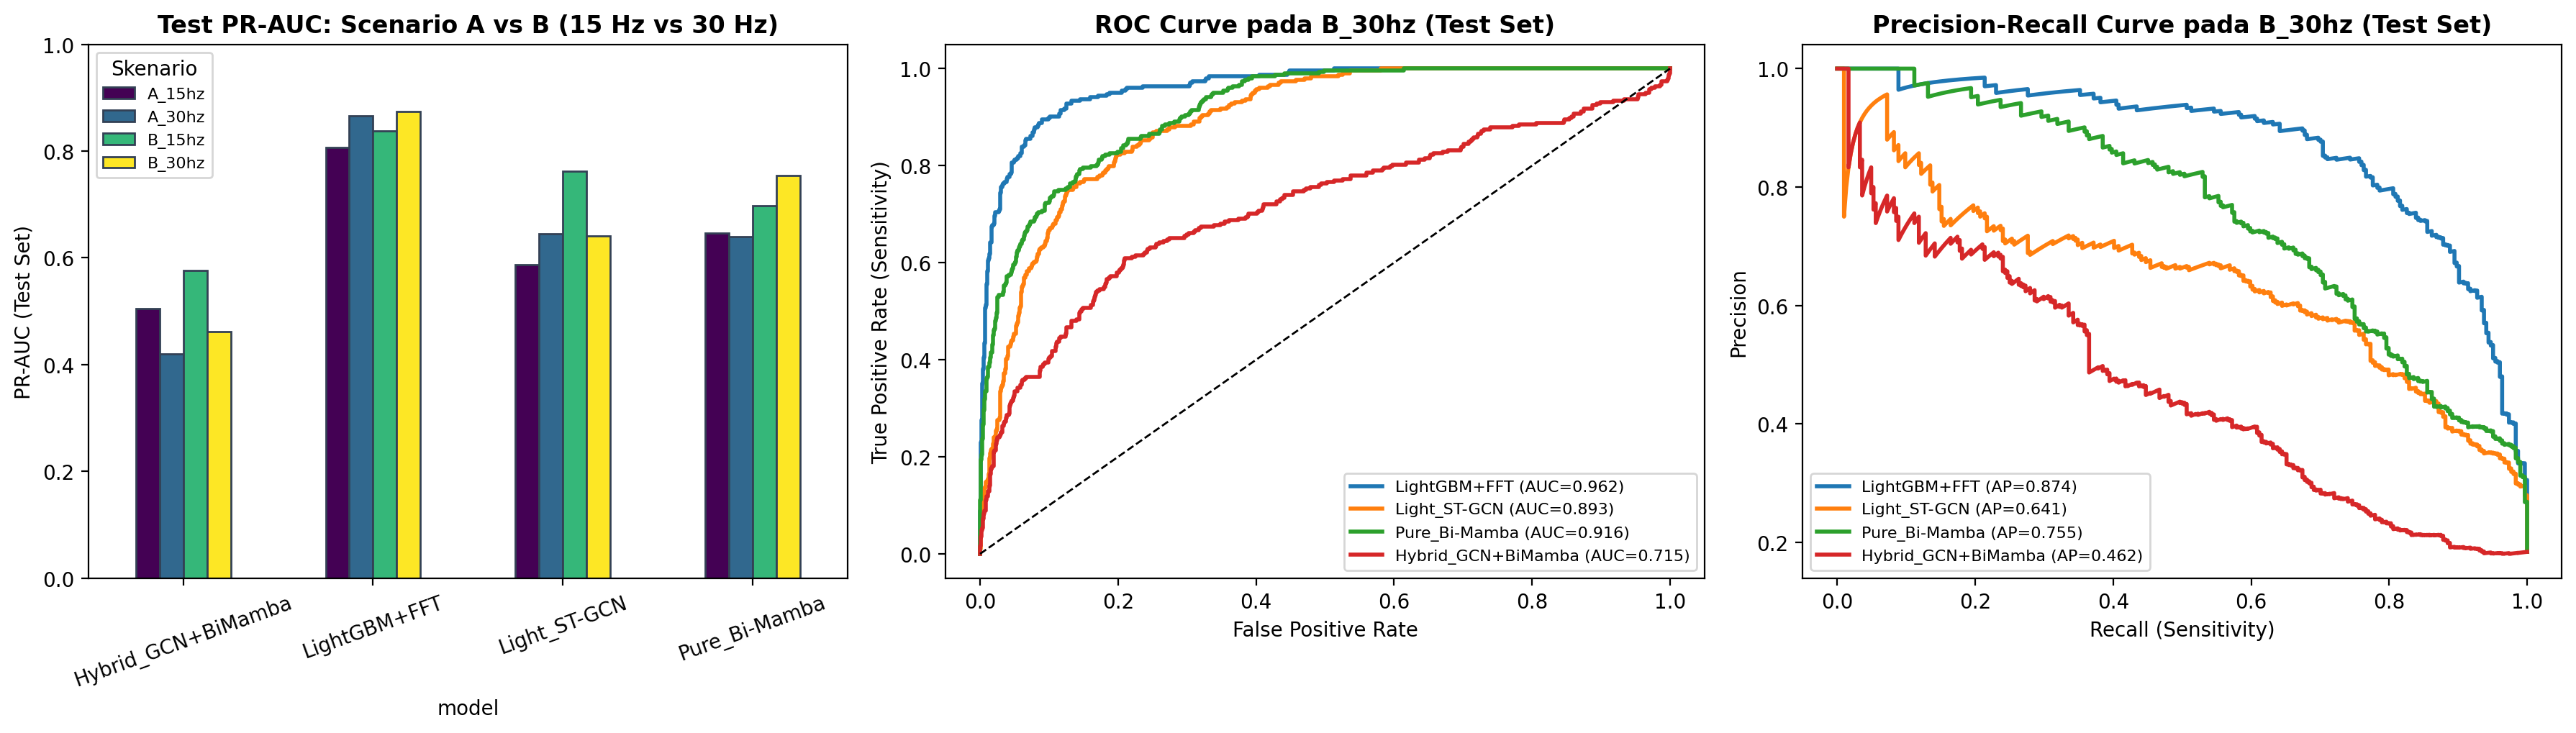

Grafik tersimpan di: /kaggle/working/mobilefog_training_results/figures/dwpose_4models_comparison.png
Tabel lengkap tersimpan di: /kaggle/working/mobilefog_training_results/results_summary.csv


In [7]:
# ==============================================================================
# VISUALISASI HASIL: KURVA ROC/PR & PERBANDINGAN 15 HZ VS 30 HZ (SCENARIO A VS B)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=200)

# Plot 1: Grouped Bar Chart Test PR-AUC (4 Model x 4 Skenario)
piv = df_results.pivot(index="model", columns="scenario", values="test_pr_auc")
piv.plot(kind="bar", ax=axes[0], colormap="viridis", edgecolor="#334155")
axes[0].set_title("Test PR-AUC: Scenario A vs B (15 Hz vs 30 Hz)", fontweight="bold")
axes[0].set_ylabel("PR-AUC (Test Set)")
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(title="Skenario", fontsize=8)

# Plot 2 & 3: ROC & PR Curve untuk Skenario terbaik (B_30hz atau skenario teratas)
best_scen = df_results.iloc[0]["scenario"]
for m_name in ["LightGBM+FFT", "Light_ST-GCN", "Pure_Bi-Mamba", "Hybrid_GCN+BiMamba"]:
    y_te, p_te, _ = saved_preds[(best_scen, m_name)]
    fpr, tpr, _ = roc_curve(y_te, p_te)
    prec, rec, _ = precision_recall_curve(y_te, p_te)
    axes[1].plot(fpr, tpr, lw=2, label=f"{m_name} (AUC={roc_auc_score(y_te, p_te):.3f})")
    axes[2].plot(rec, prec, lw=2, label=f"{m_name} (AP={average_precision_score(y_te, p_te):.3f})")

axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title(f"ROC Curve pada {best_scen} (Test Set)", fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Sensitivity)")
axes[1].legend(fontsize=8)

axes[2].set_title(f"Precision-Recall Curve pada {best_scen} (Test Set)", fontweight="bold")
axes[2].set_xlabel("Recall (Sensitivity)")
axes[2].set_ylabel("Precision")
axes[2].legend(fontsize=8)

plt.tight_layout()
fig_path = RESULTS_DIR / "figures" / "dwpose_4models_comparison.png"
plt.savefig(fig_path, dpi=220, bbox_inches="tight")
plt.show()
print(f"Grafik tersimpan di: {fig_path}")
print(f"Tabel lengkap tersimpan di: {RESULTS_DIR / 'results_summary.csv'}")


In [8]:
# ==============================================================================
# TAHAP B: 35-FOLD LOSO PARALEL PADA 2x T4 GPU (ZERO DATA LEAKAGE)
# ==============================================================================
import sys
import subprocess

if RUN_LOSO:
    if LOSO_SCENARIO == "AUTO_BEST":
        loso_tag = str(df_results.iloc[0]["scenario"])
    else:
        loso_tag = LOSO_SCENARIO
    loso_map = {t: (sub, hz) for t, sub, hz in SCENARIOS_TO_RUN}
    loso_subdir, loso_hz = loso_map[loso_tag]
    loso_scen_dir = SCEN_D_ROOT / loso_subdir
    loso_out_dir = RESULTS_DIR / f"loso_35fold_{loso_tag}"
    loso_out_dir.mkdir(parents=True, exist_ok=True)
    print(f"Menjalankan 35-Fold LOSO untuk skenario: {loso_tag} ({loso_subdir}, {int(loso_hz)} Hz)")

    # Tulis worker .py terisolasi agar 2x T4 berjalan paralel tanpa error pickle Jupyter
    loso_worker_script = RESULTS_DIR / "_loso_worker.py"
    loso_worker_script.write_text("""import json
import random
import sys
import time
from pathlib import Path

import lightgbm as lgb
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, f1_score
from torch.utils.data import DataLoader, TensorDataset


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def build_lb6_graph_A() -> np.ndarray:
    V = 6
    self_link = np.eye(V, dtype=np.float32)
    inward_edges = [(2, 0), (3, 1), (4, 2), (5, 3), (0, 1)]
    inward = np.zeros((V, V), dtype=np.float32)
    outward = np.zeros((V, V), dtype=np.float32)
    for i, j in inward_edges:
        inward[j, i] = 1.0
        outward[i, j] = 1.0

    def norm_adj(M):
        deg = M.sum(axis=0, keepdims=True)
        deg[deg == 0] = 1.0
        return M / deg

    return np.stack([norm_adj(self_link), norm_adj(inward), norm_adj(outward)], axis=0)


class SpatialGraphConv(nn.Module):
    def __init__(self, in_c: int, out_c: int, A: np.ndarray):
        super().__init__()
        self.register_buffer("A", torch.tensor(A, dtype=torch.float32))
        K, V, _ = A.shape
        self.K = K
        self.edge_mask = nn.Parameter(torch.ones(K, V, V))
        self.conv = nn.Conv2d(in_c, out_c * K, kernel_size=1)

    def forward(self, x):
        B, _, T, V = x.shape
        x = self.conv(x).view(B, self.K, -1, T, V)
        A_eff = self.A * self.edge_mask
        return torch.einsum("bkctv,kvw->bctw", x, A_eff).contiguous()


class STGCNBlock(nn.Module):
    def __init__(self, in_c: int, out_c: int, A: np.ndarray, stride: int = 1, dropout: float = 0.25):
        super().__init__()
        self.sgcn = SpatialGraphConv(in_c, out_c, A)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.tconv_dw = nn.Conv2d(out_c, out_c, kernel_size=(9, 1), stride=(stride, 1), padding=(4, 0), groups=out_c)
        self.tconv_pw = nn.Conv2d(out_c, out_c, kernel_size=1)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.drop = nn.Dropout(dropout)
        if in_c != out_c or stride != 1:
            self.residual = nn.Sequential(nn.Conv2d(in_c, out_c, kernel_size=1, stride=(stride, 1)), nn.BatchNorm2d(out_c))
        else:
            self.residual = nn.Identity()

    def forward(self, x):
        res = self.residual(x)
        h = F.relu(self.bn1(self.sgcn(x)))
        h = self.bn2(self.tconv_pw(self.tconv_dw(h)))
        return F.relu(self.drop(h) + res)


class LightweightSTGCN(nn.Module):
    def __init__(self, in_c: int, A: np.ndarray, dropout: float = 0.25):
        super().__init__()
        self.data_bn = nn.BatchNorm1d(in_c * A.shape[1])
        self.blocks = nn.Sequential(
            STGCNBlock(in_c, 32, A, stride=1, dropout=dropout),
            STGCNBlock(32, 64, A, stride=2, dropout=dropout),
            STGCNBlock(64, 64, A, stride=2, dropout=dropout),
        )
        self.head = nn.Linear(64, 1)

    def forward(self, x):
        B, C, T, V = x.shape
        x = x.permute(0, 1, 3, 2).contiguous().view(B, C * V, T)
        x = self.data_bn(x).view(B, C, V, T).permute(0, 1, 3, 2).contiguous()
        return self.head(self.blocks(x).mean(dim=(2, 3))).squeeze(-1)


class RMSNorm(nn.Module):
    def __init__(self, d_model: int, eps: float = 1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d_model))
        self.eps = eps

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps) * self.weight


class SelectiveSSM1D(nn.Module):
    def __init__(self, d_inner: int, d_state: int = 16, d_conv: int = 4):
        super().__init__()
        self.d_inner = d_inner
        self.d_state = d_state
        self.conv1d = nn.Conv1d(d_inner, d_inner, kernel_size=d_conv, padding=d_conv - 1, groups=d_inner)
        self.x_proj = nn.Linear(d_inner, d_inner + 2 * d_state, bias=False)
        self.dt_proj = nn.Linear(d_inner, d_inner, bias=True)
        A = torch.arange(1, d_state + 1, dtype=torch.float32).unsqueeze(0).repeat(d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(d_inner))

    def forward(self, u):
        B, L, D = u.shape
        x = F.silu(self.conv1d(u.transpose(1, 2))[:, :, :L].transpose(1, 2))
        dt_in, B_t, C_t = torch.split(self.x_proj(x), [D, self.d_state, self.d_state], dim=-1)
        dt = F.softplus(self.dt_proj(dt_in))
        A = -torch.exp(self.A_log)
        h = torch.zeros(B, D, self.d_state, device=u.device, dtype=u.dtype)
        ys = []
        for t in range(L):
            dt_t = dt[:, t, :].unsqueeze(-1)
            h = torch.exp(dt_t * A.unsqueeze(0)) * h + dt_t * B_t[:, t, :].unsqueeze(1) * x[:, t, :].unsqueeze(-1)
            ys.append((h * C_t[:, t, :].unsqueeze(1)).sum(dim=-1))
        return torch.stack(ys, dim=1) + x * self.D.unsqueeze(0).unsqueeze(0)


class BiMambaBlock(nn.Module):
    def __init__(self, d_model: int = 64, expand: int = 2, d_state: int = 16, dropout: float = 0.2):
        super().__init__()
        d_inner = d_model * expand
        self.norm = RMSNorm(d_model)
        self.in_proj = nn.Linear(d_model, d_inner * 2, bias=False)
        self.ssm_fwd = SelectiveSSM1D(d_inner, d_state=d_state)
        self.ssm_bwd = SelectiveSSM1D(d_inner, d_state=d_state)
        self.out_proj = nn.Linear(d_inner, d_model, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        u, z = self.in_proj(self.norm(x)).chunk(2, dim=-1)
        gate = F.silu(z)
        y_fwd = self.ssm_fwd(u) * gate
        y_bwd = torch.flip(self.ssm_bwd(torch.flip(u, dims=[1])), dims=[1]) * gate
        return x + self.drop(self.out_proj(y_fwd + y_bwd))


class PureBiMamba(nn.Module):
    def __init__(self, in_c: int, num_joints: int = 6, d_model: int = 64, n_layers: int = 2, dropout: float = 0.2):
        super().__init__()
        self.stem = nn.Sequential(nn.Linear(in_c * num_joints, d_model), nn.LayerNorm(d_model), nn.SiLU())
        self.layers = nn.ModuleList([BiMambaBlock(d_model=d_model, expand=2, d_state=16, dropout=dropout) for _ in range(n_layers)])
        self.norm_f = RMSNorm(d_model)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        B, C, T, V = x.shape
        h = self.stem(x.permute(0, 2, 1, 3).contiguous().view(B, T, C * V))
        for blk in self.layers:
            h = blk(h)
        return self.head(self.norm_f(h).mean(dim=1)).squeeze(-1)


class HybridGCNBiMamba(nn.Module):
    def __init__(self, in_c: int, A: np.ndarray, d_model: int = 64, n_mamba: int = 2, dropout: float = 0.2):
        super().__init__()
        self.gcn1 = SpatialGraphConv(in_c, 32, A)
        self.bn1 = nn.BatchNorm2d(32)
        self.gcn2 = SpatialGraphConv(32, d_model, A)
        self.bn2 = nn.BatchNorm2d(d_model)
        self.drop_g = nn.Dropout(dropout)
        self.mamba_layers = nn.ModuleList([BiMambaBlock(d_model=d_model, expand=2, d_state=16, dropout=dropout) for _ in range(n_mamba)])
        self.norm_f = RMSNorm(d_model)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        h = F.silu(self.bn1(self.gcn1(x)))
        h = self.drop_g(F.silu(self.bn2(self.gcn2(h))))
        h = h.mean(dim=-1).transpose(1, 2).contiguous()
        for blk in self.mamba_layers:
            h = blk(h)
        return self.head(self.norm_f(h).mean(dim=1)).squeeze(-1)


def extract_fft_features(X_raw: np.ndarray, fs: float) -> np.ndarray:
    N, C, T, V = X_raw.shape
    freqs = np.fft.rfftfreq(T, d=1.0 / fs)
    loco_mask = (freqs >= 0.5) & (freqs <= 3.0)
    freeze_mask = (freqs > 3.0) & (freqs <= min(8.0, 0.49 * fs))
    feats = []
    for c_idx in [0, 1, 3, 4]:
        arr = X_raw[:, c_idx, :, :]
        feats.extend([arr.mean(axis=1), arr.std(axis=1), np.max(np.abs(arr), axis=1)])
    for c_idx in [3, 4]:
        sig = X_raw[:, c_idx, :, :] - X_raw[:, c_idx, :, :].mean(axis=1, keepdims=True)
        psd = np.abs(np.fft.rfft(sig, axis=1)) ** 2
        e_loco = psd[:, loco_mask, :].sum(axis=1) + 1e-8
        e_freeze = psd[:, freeze_mask, :].sum(axis=1) + 1e-8
        feats.extend([np.log1p(e_loco), np.log1p(e_freeze), np.log1p(e_freeze / e_loco)])
    for l_j, r_j in [(0, 1), (2, 3), (4, 5)]:
        dist_xy = np.sqrt((X_raw[:, 0, :, l_j] - X_raw[:, 0, :, r_j]) ** 2 + (X_raw[:, 1, :, l_j] - X_raw[:, 1, :, r_j]) ** 2)
        asym_v = np.abs(X_raw[:, 3, :, l_j] - X_raw[:, 3, :, r_j]) + np.abs(X_raw[:, 4, :, l_j] - X_raw[:, 4, :, r_j])
        feats.extend([dist_xy.mean(axis=1, keepdims=True), dist_xy.std(axis=1, keepdims=True), asym_v.mean(axis=1, keepdims=True), asym_v.std(axis=1, keepdims=True)])
    feats.append(X_raw[:, 2, :, :].mean(axis=1))
    return np.nan_to_num(np.concatenate(feats, axis=1).astype(np.float32), nan=0.0, posinf=0.0, neginf=0.0)


def find_best_thr(y_true: np.ndarray, y_prob: np.ndarray) -> float:
    best_thr, best_f1 = 0.5, -1.0
    for thr in np.linspace(0.15, 0.85, 71):
        sc = f1_score(y_true, (y_prob >= thr).astype(np.int64), zero_division=0)
        if sc > best_f1:
            best_f1, best_thr = sc, float(thr)
    return best_thr


def fit_torch_fold(model, X_tr, y_tr, X_va, y_va, X_te, cfg, device):
    model = model.to(device)
    dl_tr = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr.astype(np.float32))), batch_size=cfg["batch_size"], shuffle=True)
    dl_va = DataLoader(TensorDataset(torch.from_numpy(X_va)), batch_size=128, shuffle=False)
    dl_te = DataLoader(TensorDataset(torch.from_numpy(X_te)), batch_size=128, shuffle=False)

    pos_w = torch.tensor([(y_tr == 0).sum() / max((y_tr == 1).sum(), 1)], dtype=torch.float32, device=device)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])

    @torch.no_grad()
    def pred(dl):
        model.eval()
        out = []
        for (xb,) in dl:
            out.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
        return np.concatenate(out)

    best_pr, best_state, bad = -1.0, None, 0
    for _ in range(cfg["epochs"]):
        model.train()
        for xb, yb in dl_tr:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()
        sched.step()
        p_va = pred(dl_va)
        pr = average_precision_score(y_va, p_va) if len(np.unique(y_va)) > 1 else 0.0
        if pr > best_pr:
            best_pr = pr
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    p_va = pred(dl_va)
    p_te = pred(dl_te)
    thr = find_best_thr(y_va, p_va)
    return p_te.astype(np.float32), float(thr)


def main():
    job = json.loads(Path(sys.argv[1]).read_text(encoding="utf-8"))
    gpu_label = job["gpu_label"]
    cfg = job["cfg"]
    fold_sids = job["fold_sids"]
    out_dir = Path(cfg["out_dir"])
    out_dir.mkdir(parents=True, exist_ok=True)

    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    A_LB6 = build_lb6_graph_A()

    # Gabungkan X MENTAH (bukan X_scaled!) dari train + val + test
    sdir = Path(cfg["scen_dir"])
    Xs, ys, sids, tids = [], [], [], []
    for sp in ["train", "val", "test"]:
        d = np.load(sdir / f"{sp}.npz", allow_pickle=True)
        Xs.append(d["X"].astype(np.float32))
        ys.append(d[cfg["label_key"]].astype(np.int64))
        sids.append(d["subject_id"].astype(str))
        tids.append(d["trial_id"].astype(str))
    X_all = np.concatenate(Xs, axis=0)
    y_all = np.concatenate(ys, axis=0)
    sid_all = np.concatenate(sids, axis=0)
    tid_all = np.concatenate(tids, axis=0)
    F_all = extract_fft_features(X_all, fs=float(cfg["hz"]))

    unique_sids = sorted(np.unique(sid_all).tolist())
    # Kelompokkan subjek FoG aktif vs kontrol 0% FoG untuk stratifikasi inner-val
    active_sids = [s for s in unique_sids if y_all[sid_all == s].sum() > 0]
    ctrl_sids = [s for s in unique_sids if y_all[sid_all == s].sum() == 0]
    in_c = int(X_all.shape[1])

    for test_sid in fold_sids:
        fold_file = out_dir / f"fold_{test_sid}.npz"
        if fold_file.exists():
            continue
        t0 = time.time()
        fold_idx = unique_sids.index(test_sid)
        rng = np.random.default_rng(cfg["seed"] + fold_idx)

        rem_active = [s for s in active_sids if s != test_sid]
        rem_ctrl = [s for s in ctrl_sids if s != test_sid]
        n_val = cfg["inner_val_subjects"]
        n_val_ctrl = min(1, len(rem_ctrl))
        n_val_act = min(n_val - n_val_ctrl, len(rem_active))
        val_sids = set(rng.choice(rem_active, size=n_val_act, replace=False).tolist()) | set(rng.choice(rem_ctrl, size=n_val_ctrl, replace=False).tolist())

        te_mask = sid_all == test_sid
        va_mask = np.isin(sid_all, list(val_sids))
        tr_mask = ~(te_mask | va_mask)

        # ZERO DATA LEAKAGE: Fit StandardScaler HANYA di X_tr fold ini!
        X_tr_raw, y_tr = X_all[tr_mask], y_all[tr_mask]
        X_va_raw, y_va = X_all[va_mask], y_all[va_mask]
        X_te_raw, y_te = X_all[te_mask], y_all[te_mask]

        mean = X_tr_raw.mean(axis=(0, 2, 3), keepdims=True)
        std = X_tr_raw.std(axis=(0, 2, 3), keepdims=True) + 1e-6
        X_tr = ((X_tr_raw - mean) / std).astype(np.float32)
        X_va = ((X_va_raw - mean) / std).astype(np.float32)
        X_te = ((X_te_raw - mean) / std).astype(np.float32)

        # 1. LightGBM + FFT
        seed_everything(cfg["seed"] + fold_idx)
        pos_w = float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))
        clf = lgb.LGBMClassifier(
            n_estimators=500, learning_rate=0.03, num_leaves=31,
            colsample_bytree=0.8, subsample=0.8, scale_pos_weight=pos_w,
            random_state=cfg["seed"] + fold_idx, n_jobs=-1, verbose=-1
        )
        clf.fit(F_all[tr_mask], y_tr, eval_set=[(F_all[va_mask], y_va)], eval_metric="average_precision",
                callbacks=[lgb.early_stopping(40, verbose=False)])
        p_va_lgb = clf.predict_proba(F_all[va_mask])[:, 1]
        p_te_lgb = clf.predict_proba(F_all[te_mask])[:, 1].astype(np.float32)
        thr_lgb = find_best_thr(y_va, p_va_lgb)

        # 2. Light ST-GCN-cls
        seed_everything(cfg["seed"] + fold_idx)
        p_te_stgcn, thr_stgcn = fit_torch_fold(LightweightSTGCN(in_c, A_LB6), X_tr, y_tr, X_va, y_va, X_te, cfg, device)

        # 3. Pure Bi-Mamba
        seed_everything(cfg["seed"] + fold_idx)
        p_te_mamba, thr_mamba = fit_torch_fold(PureBiMamba(in_c, 6, 64, 2), X_tr, y_tr, X_va, y_va, X_te, cfg, device)

        # 4. Hybrid GCN + Bi-Mamba
        seed_everything(cfg["seed"] + fold_idx)
        p_te_hyb, thr_hyb = fit_torch_fold(HybridGCNBiMamba(in_c, A_LB6, 64, 2), X_tr, y_tr, X_va, y_va, X_te, cfg, device)

        np.savez_compressed(
            fold_file,
            test_sid=np.array(test_sid),
            indices=np.where(te_mask)[0].astype(np.int64),
            y_te=y_te,
            trial_id=tid_all[te_mask],
            p_lgbm=p_te_lgb, thr_lgbm=np.float32(thr_lgb),
            p_stgcn=p_te_stgcn, thr_stgcn=np.float32(thr_stgcn),
            p_mamba=p_te_mamba, thr_mamba=np.float32(thr_mamba),
            p_hybrid=p_te_hyb, thr_hybrid=np.float32(thr_hyb),
        )
        print(f"[GPU {gpu_label}] LOSO Fold Subjek {test_sid} selesai ({len(y_te)} win, FoG={y_te.mean()*100:.1f}%) dalam {time.time()-t0:.1f}s", flush=True)


if __name__ == "__main__":
    main()
""", encoding="utf-8")

    # Ambil seluruh 35 subject_id unik dari train + val + test
    all_sids = set()
    for sp in ["train", "val", "test"]:
        d_tmp = np.load(loso_scen_dir / f"{sp}.npz", allow_pickle=True)
        all_sids.update(d_tmp["subject_id"].astype(str).tolist())
    all_sids = sorted(all_sids)
    print(f"Total subjek unik untuk LOSO: {len(all_sids)}")

    loso_cfg = {
        "scen_dir": str(loso_scen_dir),
        "out_dir": str(loso_out_dir),
        "hz": float(loso_hz),
        "label_key": LABEL_KEY,
        "epochs": LOSO_EPOCHS,
        "patience": LOSO_PATIENCE,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "weight_decay": WEIGHT_DECAY,
        "grad_clip": GRAD_CLIP,
        "inner_val_subjects": LOSO_INNER_VAL_SUBJECTS,
        "seed": SEED,
    }

    t_loso = time.time()
    n_gpus = max(1, torch.cuda.device_count())
    shards = [all_sids[i::n_gpus] for i in range(n_gpus)]
    procs = []
    for gid in range(n_gpus):
        job_f = RESULTS_DIR / f"_loso_job_gpu{gid}.json"
        job_f.write_text(json.dumps({"gpu_label": gid, "cfg": loso_cfg, "fold_sids": shards[gid]}), encoding="utf-8")
        env = os.environ.copy()
        if torch.cuda.is_available():
            env["CUDA_VISIBLE_DEVICES"] = str(gid)
        p = subprocess.Popen([sys.executable, str(loso_worker_script), str(job_f)], env=env)
        procs.append((gid, p))

    for gid, p in procs:
        rc = p.wait()
        assert rc == 0, f"LOSO Worker GPU {gid} gagal dengan exitcode {rc}"
    print(f"Seluruh {len(all_sids)} fold LOSO selesai dalam {time.time() - t_loso:.1f} detik.")


Menjalankan 35-Fold LOSO untuk skenario: B_15hz (from_B_denoised_hampel_accel_15hz, 15 Hz)
Total subjek unik untuk LOSO: 35


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[GPU 0] LOSO Fold Subjek 01 selesai (236 win, FoG=96.6%) dalam 311.6s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[GPU 1] LOSO Fold Subjek 02 selesai (118 win, FoG=89.8%) dalam 362.3s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (53 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[GPU 1] LOSO Fold Subjek 34 selesai (118 win, FoG=20.3%) dalam 238.0s
[GPU 0] LOSO Fold Subjek 33 selesai (118 win, FoG=33.9%) dalam 354.9s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[GPU 0] LOSO Fold Subjek 35 selesai (354 win, FoG=0.0%) dalam 255.2s
Seluruh 35 fold LOSO selesai dalam 5677.8 detik.



=== HASIL 35-FOLD LOSO (B_15hz) — GLOBAL OOF & PER-SUBJECT ===


,loso_scenario,model,folds,oof_roc_auc,oof_pr_auc,oof_f1_raw,oof_f1_pp,oof_sens_pp,oof_spec_pp,oof_bal_acc_pp,subj26_pr_auc_mean_std,subj35_spec_mean_std
0,B_15hz,Pure_Bi-Mamba,35,0.9057,0.7413,0.6854,0.6961,0.7166,0.9192,0.8179,0.536 ± 0.299,0.821 ± 0.259
1,B_15hz,Light_ST-GCN,35,0.8958,0.7194,0.6312,0.6402,0.6878,0.8913,0.7895,0.516 ± 0.331,0.813 ± 0.254
2,B_15hz,LightGBM+FFT,35,0.9046,0.6983,0.6607,0.6757,0.6696,0.9263,0.7980,0.562 ± 0.344,0.870 ± 0.224
3,B_15hz,Hybrid_GCN+BiMamba,35,0.8318,0.6292,0.5688,0.5834,0.5781,0.9047,0.7414,0.464 ± 0.348,0.796 ± 0.279


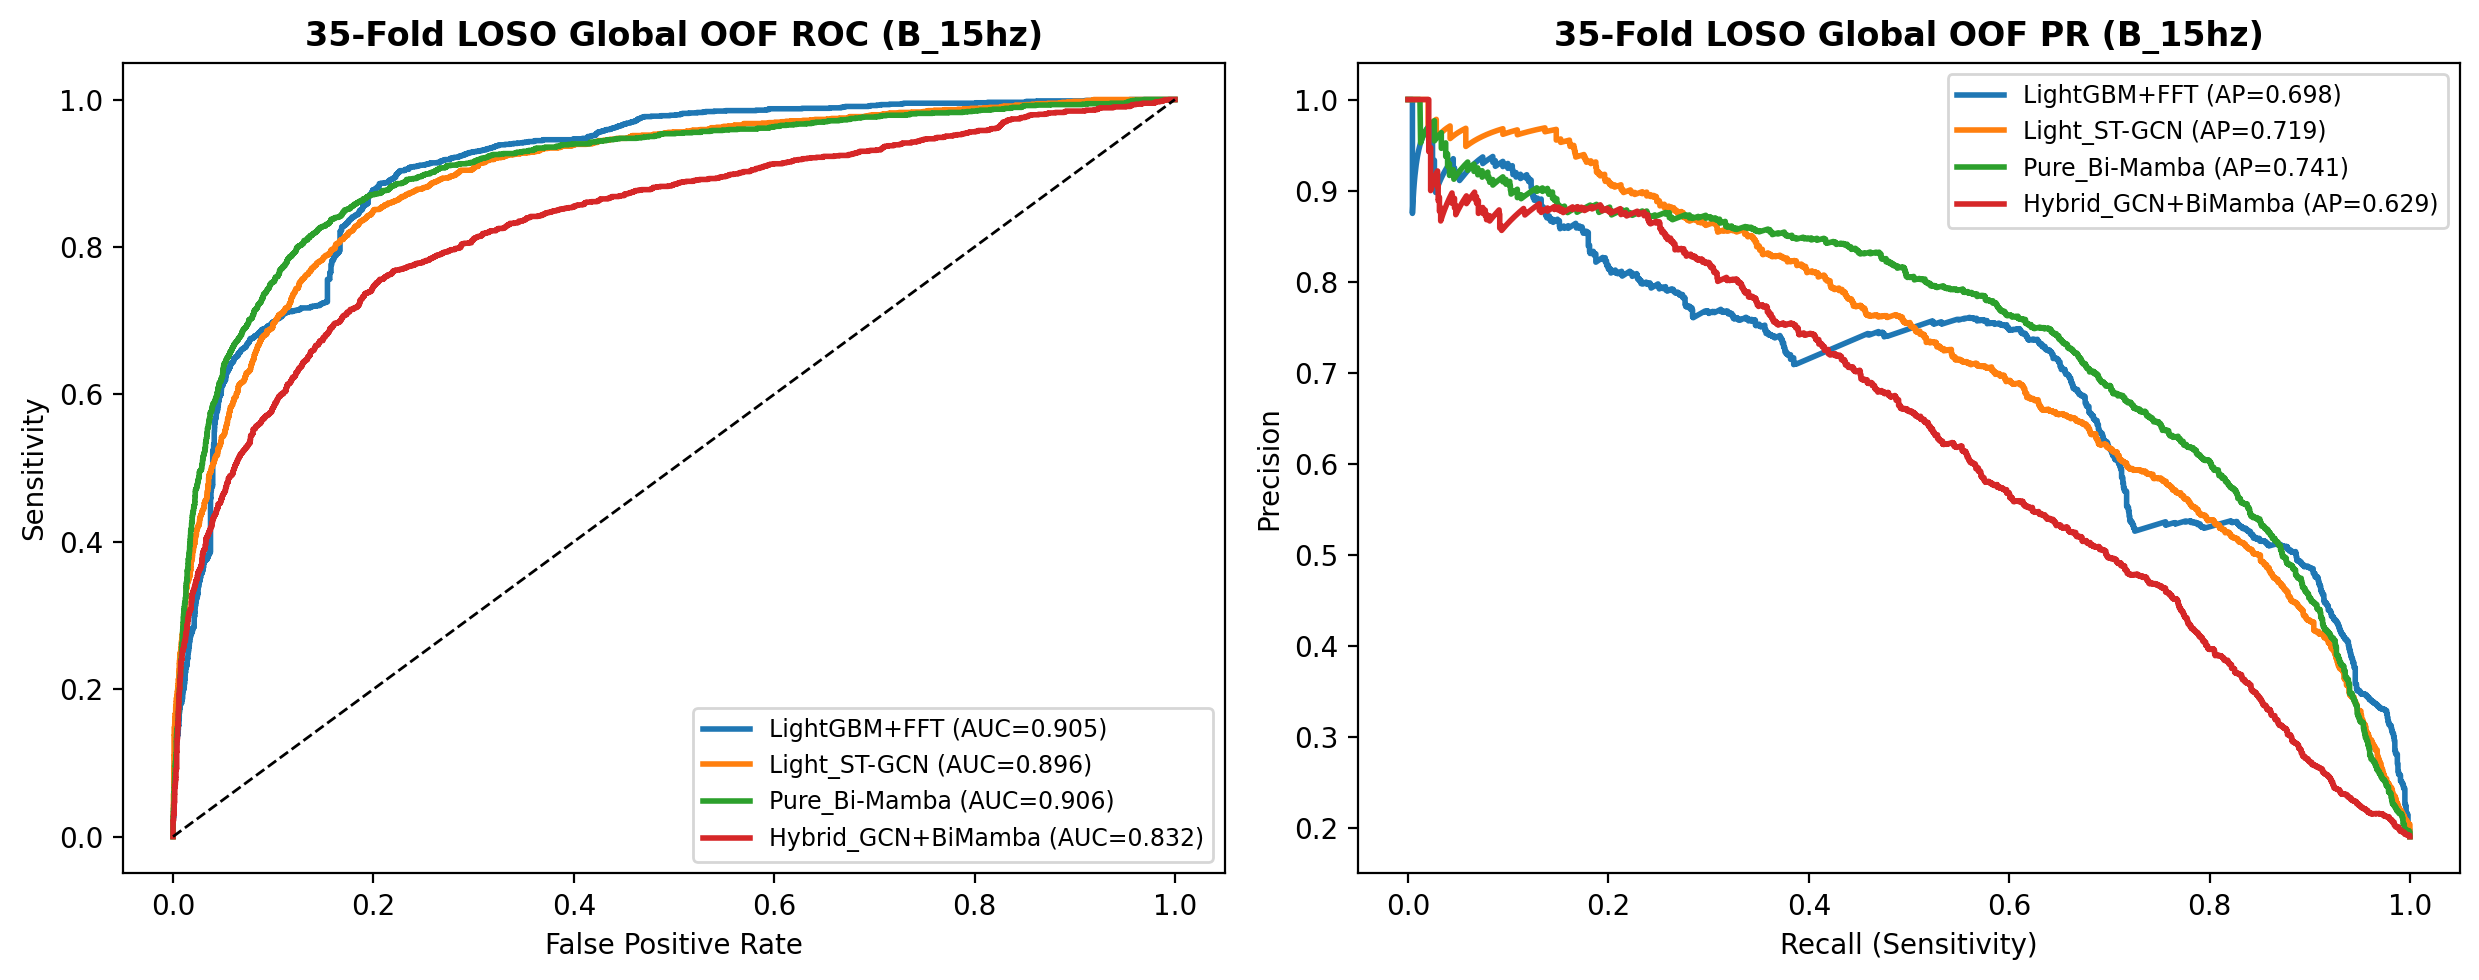

Grafik LOSO tersimpan di: /kaggle/working/mobilefog_training_results/figures/loso_35fold_B_15hz.png


In [9]:
# ==============================================================================
# AGREGASI & VISUALISASI HASIL 35-FOLD LOSO (GLOBAL OOF + PER-SUBJECT MEAN±STD)
# ==============================================================================
if RUN_LOSO:
    model_specs = [
        ("LightGBM+FFT", "p_lgbm", "thr_lgbm"),
        ("Light_ST-GCN", "p_stgcn", "thr_stgcn"),
        ("Pure_Bi-Mamba", "p_mamba", "thr_mamba"),
        ("Hybrid_GCN+BiMamba", "p_hybrid", "thr_hybrid"),
    ]
    fold_files = sorted(loso_out_dir.glob("fold_*.npz"))
    assert len(fold_files) > 0, "Tidak ada file fold LOSO yang ditemukan!"

    oof_rows = []
    subj_rows = []
    oof_curves = {}

    for m_name, p_key, thr_key in model_specs:
        y_all_list, p_all_list, pred_raw_list, pred_pp_list, tid_list = [], [], [], [], []
        subj_aucs, subj_prs, subj_f1s, subj_sens, subj_specs = [], [], [], [], []

        for ff in fold_files:
            d = np.load(ff, allow_pickle=True)
            sid = str(d["test_sid"])
            y_te = d["y_te"].astype(np.int64)
            p_te = d[p_key].astype(np.float32)
            thr = float(d[thr_key])
            tids = d["trial_id"].astype(str)

            pr_raw = (p_te >= thr).astype(np.int64)
            pr_pp = apply_min_duration_filter(pr_raw, tids, min_run=MIN_RUN_WINDOWS)

            y_all_list.append(y_te)
            p_all_list.append(p_te)
            pred_raw_list.append(pr_raw)
            pred_pp_list.append(pr_pp)
            tid_list.append(tids)

            tn, fp, fn, tp = confusion_matrix(y_te, pr_pp, labels=[0, 1]).ravel()
            spec = tn / max(tn + fp, 1)
            subj_specs.append(spec)

            is_active = int(y_te.sum() > 0)
            if is_active:
                s_auc = roc_auc_score(y_te, p_te)
                s_pr = average_precision_score(y_te, p_te)
                s_f1 = f1_score(y_te, pr_pp, zero_division=0)
                s_sens = tp / max(tp + fn, 1)
                subj_aucs.append(s_auc); subj_prs.append(s_pr); subj_f1s.append(s_f1); subj_sens.append(s_sens)
            else:
                s_auc = s_pr = s_f1 = s_sens = np.nan

            subj_rows.append({
                "model": m_name, "subject_id": sid, "fog_active": is_active,
                "n_windows": len(y_te), "fog_pct": round(y_te.mean() * 100, 2),
                "roc_auc": s_auc, "pr_auc": s_pr, "f1_pp": s_f1, "sens_pp": s_sens, "spec_pp": spec,
            })

        y_oof = np.concatenate(y_all_list)
        p_oof = np.concatenate(p_all_list)
        pr_raw_oof = np.concatenate(pred_raw_list)
        pr_pp_oof = np.concatenate(pred_pp_list)
        tn, fp, fn, tp = confusion_matrix(y_oof, pr_pp_oof, labels=[0, 1]).ravel()
        sens_oof = tp / max(tp + fn, 1)
        spec_oof = tn / max(tn + fp, 1)
        oof_curves[m_name] = (y_oof, p_oof)

        oof_rows.append({
            "loso_scenario": loso_tag,
            "model": m_name,
            "folds": len(fold_files),
            "oof_roc_auc": round(float(roc_auc_score(y_oof, p_oof)), 4),
            "oof_pr_auc": round(float(average_precision_score(y_oof, p_oof)), 4),
            "oof_f1_raw": round(float(f1_score(y_oof, pr_raw_oof, zero_division=0)), 4),
            "oof_f1_pp": round(float(f1_score(y_oof, pr_pp_oof, zero_division=0)), 4),
            "oof_sens_pp": round(float(sens_oof), 4),
            "oof_spec_pp": round(float(spec_oof), 4),
            "oof_bal_acc_pp": round(float(0.5 * (sens_oof + spec_oof)), 4),
            "subj26_pr_auc_mean_std": f"{np.mean(subj_prs):.3f} ± {np.std(subj_prs):.3f}" if subj_prs else "N/A",
            "subj35_spec_mean_std": f"{np.mean(subj_specs):.3f} ± {np.std(subj_specs):.3f}",
        })

    df_loso_oof = pd.DataFrame(oof_rows).sort_values("oof_pr_auc", ascending=False).reset_index(drop=True)
    df_loso_subj = pd.DataFrame(subj_rows)
    df_loso_oof.to_csv(RESULTS_DIR / f"loso_oof_summary_{loso_tag}.csv", index=False)
    df_loso_subj.to_csv(RESULTS_DIR / f"loso_per_subject_{loso_tag}.csv", index=False)

    print(f"\n=== HASIL 35-FOLD LOSO ({loso_tag}) — GLOBAL OOF & PER-SUBJECT ===")
    display(df_loso_oof)

    # Plot OOF ROC & PR Curve
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0), dpi=200)
    for m_name, _, _ in model_specs:
        y_oof, p_oof = oof_curves[m_name]
        fpr, tpr, _ = roc_curve(y_oof, p_oof)
        prec, rec, _ = precision_recall_curve(y_oof, p_oof)
        axes[0].plot(fpr, tpr, lw=2, label=f"{m_name} (AUC={roc_auc_score(y_oof, p_oof):.3f})")
        axes[1].plot(rec, prec, lw=2, label=f"{m_name} (AP={average_precision_score(y_oof, p_oof):.3f})")
    axes[0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0].set_title(f"35-Fold LOSO Global OOF ROC ({loso_tag})", fontweight="bold")
    axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("Sensitivity"); axes[0].legend(fontsize=8.5)
    axes[1].set_title(f"35-Fold LOSO Global OOF PR ({loso_tag})", fontweight="bold")
    axes[1].set_xlabel("Recall (Sensitivity)"); axes[1].set_ylabel("Precision"); axes[1].legend(fontsize=8.5)
    plt.tight_layout()
    loso_fig = RESULTS_DIR / "figures" / f"loso_35fold_{loso_tag}.png"
    plt.savefig(loso_fig, dpi=220, bbox_inches="tight")
    plt.show()
    print(f"Grafik LOSO tersimpan di: {loso_fig}")
